In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split

In [2]:
train = pd.read_csv("FNN and CNN/Sign Language MNIST/sign_mnist_train.csv")
test = pd.read_csv("FNN and CNN/Sign Language MNIST/sign_mnist_test.csv")

print("Training data:", train.shape)
print("Testing data:", test.shape)

Training data: (27455, 785)
Testing data: (7172, 785)


In [3]:
x = train.iloc[:, 1:].values
y = train.iloc[:, 0].values

x_test = test.iloc[:, 1:].values
y_test = test.iloc[:, 0].values

In [4]:
x = x / 255.0
x_test = x_test / 255.0

x = x.reshape(-1, 28, 28, 1)
x_test = x_test.reshape(-1, 28, 28, 1)

print("Training shape:", x.shape)
print("Testing shape:", x_test.shape)

Training shape: (27455, 28, 28, 1)
Testing shape: (7172, 28, 28, 1)


In [5]:
x_train, x_val, y_train, y_val = train_test_split(
    x, y, test_size=0.1, random_state=42, stratify=y
)

print("Training:", x_train.shape)
print("Validation:", x_val.shape)

Training: (24709, 28, 28, 1)
Validation: (2746, 28, 28, 1)


In [6]:
model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(25, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 226,969 (886.60 KB)

 Trainable params: 226,969 (886.60 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.6089 - loss: 1.3347 - val_accuracy: 0.8299 - val_loss: 0.4561
Epoch 2/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9537 - loss: 0.1810 - val_accuracy: 0.9927 - val_loss: 0.0680
Epoch 3/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9979 - loss: 0.0308 - val_accuracy: 1.0000 - val_loss: 0.0126
Epoch 4/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9999 - loss: 0.0089 - val_accuracy: 1.0000 - val_loss: 0.0056
Epoch 5/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 1.0000 - loss: 0.0040 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 6/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 1.0000 - loss: 0.0021 - val_accuracy: 1.0000 - val_loss: 0.0016
Epoch 7/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 1.0000 - loss: 0.0012 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 8/10
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 1.0000 - loss: 7.9105e-04 - val_

In [9]:
loss, accuracy = model.evaluate(x_test, y_test)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8974 - loss: 0.3907
Test Loss: 0.39070597290992737
Test Accuracy: 0.89737868309021


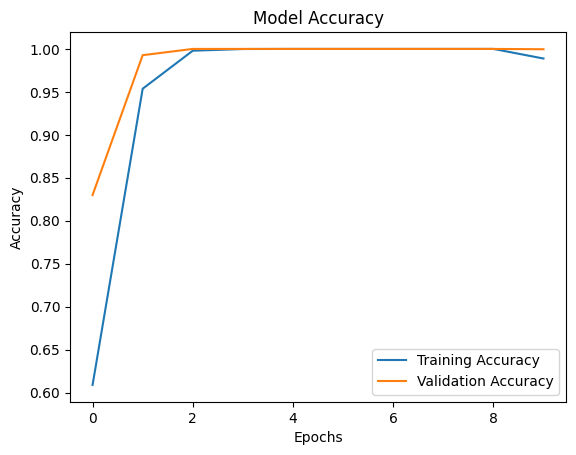

In [10]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

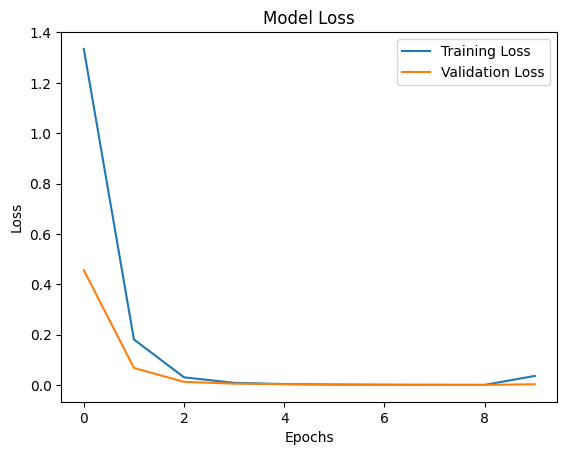

In [11]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [12]:
prediction = model.predict(x_test[:1])

print("Predicted Label:", np.argmax(prediction[0]))
print("Actual Label:", y_test[0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
Predicted Label: 6
Actual Label: 6
